# 12 · Gaussian Naive Bayes: tune, evaluate, save

Final-model notebook for **Team Plug Detectives (EC5203)**. One of eight model notebooks (05–12), compared side by side under the same rules in **13_model_comparison**.
All eight use the **same data, the same 20 features (chosen in 04 step 4) and the same house-grouped CV**, so their scores are directly comparable.

**Gaussian Naive Bayes** = Bayes' rule with two simplifying assumptions: each feature follows a normal (bell-shaped) distribution within each appliance, and features are independent of each other given the appliance. Training only estimates a mean and a variance per feature per class.

| Step | What it does |
|---|---|
| 1 | Load features, split into 46 dev homes / 10 locked test homes |
| 2 | Score the default model, then grid-search the settings (groups passed, so no home is in train and validation) |
| 3 | Robustness: re-score default vs tuned on 5 new house splits; keep the tuned one only if it wins by more than one standard error |
| 4 | Train on all dev homes, test once on the 10 unseen homes: macro-F1, per-class report, confusion matrix, 95% interval |
| 5 | Train on all 56 homes, save `model_nb.joblib`, self-checks. Then: `python predict_nb.py submetered_new/1.csv` |

## Step 1 · Setup

In [1]:
from pathlib import Path
import sys, json
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler, QuantileTransformer, PowerTransformer
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, GridSearchCV
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

DATA = Path.home() / "Documents" / "10084619"
MODEL_FILE = DATA / "model_nb.joblib"

features = pd.read_csv(DATA / "features.csv").merge(pd.read_csv(DATA / "split.csv")[["id", "split"]], on="id")

# The 20 features chosen in 04 step 4 (top 20 by permutation importance, checked on 5 CV seeds)
FINAL = ["inrush_ratio", "hf_noise_ratio", "transient_energy", "vi_mid_slope", "p_w",
         "h3_h1", "conduction_angle", "dpf", "i_peak", "vi_area",
         "inrush_duration", "pf", "vi_width0", "half_cycle_asym", "vi_curvature",
         "phase_deg", "v_at_ipeak", "settling_time", "h7_h1", "kurtosis"]
assert set(FINAL) <= set(json.loads((DATA / "feature_shortlist.json").read_text(encoding="utf-8"))["features"])

dev = features[features["split"] == "dev"].reset_index(drop=True)
test = features[features["split"] == "test"].reset_index(drop=True)
X_dev, y_dev, g_dev = dev[FINAL], dev["type"], dev["location"]
X_test, y_test = test[FINAL], test["type"]           # locked until step 4

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

def evaluate(model, seed=0):
    """House-grouped 5-fold CV on dev: fold-mean macro-F1 and accuracy, with standard errors."""
    cv_s = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    r = cross_validate(model, X_dev, y_dev, groups=g_dev, cv=cv_s,
                       scoring={"f1": "f1_macro", "acc": "accuracy"}, n_jobs=-1)
    se = lambda s: s.std(ddof=1) / np.sqrt(len(s))
    return {"macro_f1": round(float(r["test_f1"].mean()), 4), "f1_se": round(float(se(r["test_f1"])), 4),
            "accuracy": round(float(r["test_acc"].mean()), 4), "acc_se": round(float(se(r["test_acc"])), 4)}

assert (len(dev), len(test)) == (1447, 363)
assert not set(dev["location"]) & set(test["location"]), "a home is in both dev and test"
print(f"dev: {len(dev)} recordings, {g_dev.nunique()} homes | test: {len(test)} recordings, "
      f"{test['location'].nunique()} homes (locked) | {len(FINAL)} features | {y_dev.nunique()} appliance types")

dev: 1447 recordings, 46 homes | test: 363 recordings, 10 homes (locked) | 20 features | 11 appliance types


## Step 2 · Default model, then grid search

`var_smoothing` × imputer × transform = 5 × 2 × 3 = **30 settings**.

Naive Bayes assumes each feature is bell-shaped within each class, so the transform is the main thing to tune:

- **Imputer:** median only, or median plus a 0/1 "was missing" column per feature.
- **Transform:** `StandardScaler` (keeps the shape; same as no transform for this model), `QuantileTransformer` or `PowerTransformer` (both reshape skewed features towards a bell curve).

In [2]:
base = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), GaussianNB())
step = base.steps[-1][0]
model_grid = {"var_smoothing": [1e-9, 1e-5, 1e-3, 1e-2, 1e-1]}   # variance added for stability (1e-9 = default)
grid = {"simpleimputer": [SimpleImputer(strategy="median"),                       # fill NaN with the median
                          SimpleImputer(strategy="median", add_indicator=True)],  # + a 0/1 "was missing" column
        "standardscaler": [StandardScaler(),                                       # keep the shape
                           QuantileTransformer(output_distribution="normal", random_state=0),  # force a bell shape
                           PowerTransformer()],                                    # Yeo-Johnson: reduce skew
        **{f"{step}__{k}": v for k, v in model_grid.items()}}

print("Default settings:", evaluate(base))

gs = GridSearchCV(base, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
gs.fit(X_dev, y_dev, groups=g_dev)
res = pd.DataFrame(gs.cv_results_)
res["se"] = res["std_test_score"] / np.sqrt(cv.get_n_splits())
top = res.sort_values("rank_test_score").head(8)
top = top[[c for c in res if c.startswith("param_")] + ["mean_test_score", "se"]]
top.columns = [c.split("__")[-1].replace("param_", "") for c in top.columns]
print(f"Grid search: {len(res)} settings x {cv.get_n_splits()} folds | best macro-F1 {gs.best_score_:.3f}")
display(top.round(3))
tuned = gs.best_estimator_

Default settings: {'macro_f1': 0.7549, 'f1_se': 0.0077, 'accuracy': 0.8257, 'acc_se': 0.0127}


Grid search: 30 settings x 5 folds | best macro-F1 0.765


,var_smoothing,simpleimputer,standardscaler,mean_test_score,se
15,0.001,"SimpleImputer(add_indicator=True, strategy='me...",StandardScaler(),0.765,0.015
19,0.010,SimpleImputer(strategy='median'),QuantileTransformer(output_distribution='norma...,0.762,0.029
16,0.001,"SimpleImputer(add_indicator=True, strategy='me...",QuantileTransformer(output_distribution='norma...,0.761,0.024
20,0.010,SimpleImputer(strategy='median'),PowerTransformer(),0.759,0.010
6,0.000,SimpleImputer(strategy='median'),StandardScaler(),0.758,0.009
13,0.001,SimpleImputer(strategy='median'),QuantileTransformer(output_distribution='norma...,0.757,0.023
0,0.000,SimpleImputer(strategy='median'),StandardScaler(),0.755,0.007
12,0.001,SimpleImputer(strategy='median'),StandardScaler(),0.753,0.007


## Step 3 · Robustness check, then choose

The grid search picked its winner on one CV split (seed 0), so part of its win can be luck. In 04 step 5, Extra Trees tied Random Forest on seed 0 and lost on five other splits.
Rule: re-score **default** and **tuned** on 5 new house splits (seeds 1–5). Keep the tuned model only if it beats the default by more than one standard error; otherwise keep the simpler default.

In [3]:
rows = [{"default": evaluate(base, s)["macro_f1"], "tuned": evaluate(tuned, s)["macro_f1"]} for s in range(1, 6)]
robust = pd.DataFrame(rows, index=pd.Index(range(1, 6), name="CV seed"))
display(robust.round(3))

gain = robust["tuned"] - robust["default"]
gain_se = gain.std(ddof=1) / np.sqrt(len(gain))
use_tuned = gain.mean() > gain_se
model = tuned if use_tuned else base
params = {k.split("__")[-1]: str(model.get_params()[k]) for k in grid}     # settings that were searched
cv_score = evaluate(model)

print(f"tuned - default: {gain.mean():+.3f} ± {gain_se:.3f} (mean ± SE over 5 seeds) "
      f"-> using the {'TUNED' if use_tuned else 'DEFAULT'} settings")
print("Chosen settings:", params)
print("Chosen model, grouped CV on dev:", cv_score)

,default,tuned
CV seed,,
1,0.759,0.756
2,0.760,0.758
3,0.755,0.765
4,0.751,0.763
5,0.757,0.766


tuned - default: +0.005 ± 0.003 (mean ± SE over 5 seeds) -> using the TUNED settings
Chosen settings: {'simpleimputer': "SimpleImputer(add_indicator=True, strategy='median')", 'standardscaler': 'StandardScaler()', 'var_smoothing': '0.001'}
Chosen model, grouped CV on dev: {'macro_f1': 0.7651, 'f1_se': 0.0162, 'accuracy': 0.8326, 'acc_se': 0.0119}


## Step 4 · Test on the 10 locked homes (first and only look)

Train on all 46 dev homes, predict the 10 test homes nobody has touched. The confusion matrix shows, for each true appliance (row), where its recordings went (columns), as % of that row. The 95% interval comes from resampling the 10 test homes 2,000 times.

TEST (10 unseen homes): macro-F1 0.745 | accuracy 0.791


,precision,recall,f1-score,support
Air Conditioner,0.828,0.453,0.585,53.000
Compact Fluorescent Lamp,0.978,1.000,0.989,45.000
Fan,0.524,0.629,0.571,35.000
Fridge,0.405,0.600,0.484,25.000
Hairdryer,0.806,1.000,0.893,50.000
Heater,1.000,0.357,0.526,14.000
Incandescent Light Bulb,0.824,0.966,0.889,29.000
Laptop,1.000,0.975,0.987,40.000
Microwave,0.930,0.976,0.952,41.000
Vacuum,1.000,0.933,0.966,15.000


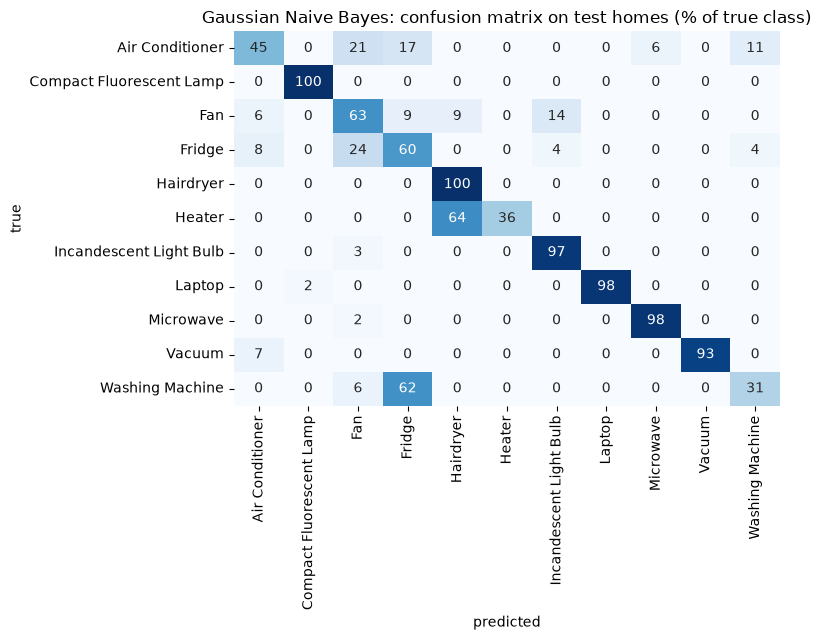

,,errors
true,predicted,
Air Conditioner,Fan,11
Washing Machine,Fridge,10
Air Conditioner,Fridge,9
Heater,Hairdryer,9
Air Conditioner,Washing Machine,6
Fridge,Fan,6


95% interval for test macro-F1 (resampling homes): 0.581 – 0.838


In [4]:
# 4a. Scores on unseen homes
model.fit(X_dev, y_dev)
y_pred = pd.Series(model.predict(X_test), index=y_test.index)
test_f1, test_acc = f1_score(y_test, y_pred, average="macro"), accuracy_score(y_test, y_pred)
print(f"TEST (10 unseen homes): macro-F1 {test_f1:.3f} | accuracy {test_acc:.3f}")
display(pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T.round(3))

# 4b. Confusion matrix (% of each true class) and the biggest confusions
labels = sorted(features["type"].unique())
cm = pd.DataFrame(confusion_matrix(y_test, y_pred, labels=labels), index=labels, columns=labels)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm.div(cm.sum(axis=1), axis=0) * 100, annot=True, fmt=".0f", cmap="Blues", cbar=False)
plt.xlabel("predicted"); plt.ylabel("true")
plt.title("Gaussian Naive Bayes: confusion matrix on test homes (% of true class)")
plt.tight_layout(); plt.show()
off = cm.where(~np.eye(len(labels), dtype=bool)).stack().dropna().astype(int)
display(off[off > 0].sort_values(ascending=False).head(6).rename("errors").rename_axis(["true", "predicted"]).to_frame())

# 4c. 95% interval for test macro-F1 (bootstrap over homes)
g_test = test["location"].to_numpy(); homes = np.unique(g_test); rng = np.random.default_rng(0)
boots = []
for _ in range(2000):
    idx = np.concatenate([np.flatnonzero(g_test == h) for h in rng.choice(homes, size=len(homes))])
    yt, yp = y_test.to_numpy()[idx], y_pred.to_numpy()[idx]
    boots.append(f1_score(yt, yp, average="macro", labels=np.unique(yt)))
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"95% interval for test macro-F1 (resampling homes): {lo:.3f} – {hi:.3f}")

## Step 5 · Train on all 56 homes and save

The deployment model uses the settings chosen in step 3, trained on every recording (dev + test). Its honest scores are the ones from steps 3–4, which are stored with it.
Self-checks: the saved file reloads to identical predictions, and `plaid_features.py` (used by `predict_nb.py`) reproduces `features.csv`, so there is no training-serving skew.

In [5]:
final_model = clone(model).fit(features[FINAL], features["type"])
bundle = {
    "pipeline": final_model,
    "model": "Gaussian Naive Bayes",
    "params": params,
    "features": FINAL,
    "classes": list(final_model.classes_),
    "trained_on": f"{len(features)} recordings, {features['location'].nunique()} homes (PLAID submetered)",
    "scores": {"cv_macro_f1_dev": cv_score["macro_f1"],
               "test_macro_f1": round(float(test_f1), 3),
               "test_macro_f1_95ci": [round(float(lo), 3), round(float(hi), 3)],
               "test_accuracy": round(float(test_acc), 3)},
    "sklearn_version": sklearn.__version__,
    "saved": str(date.today()),
}
joblib.dump(bundle, MODEL_FILE, compress=3)

# Self-checks
loaded = joblib.load(MODEL_FILE)
assert (loaded["pipeline"].predict(features[FINAL]) == final_model.predict(features[FINAL])).all()
sys.path.insert(0, str(DATA))
from plaid_features import load_wave, extract_features
for k in features["id"].sample(5, random_state=0):
    f_new = pd.Series(extract_features(*load_wave(DATA / "submetered_new" / f"{k}.csv")))[FINAL].astype(float)
    f_old = features.loc[features["id"] == k, FINAL].iloc[0].astype(float)
    assert np.allclose(f_new, f_old, equal_nan=True), f"feature mismatch for id {k}"

print(f"✓ saved {MODEL_FILE.name} ({MODEL_FILE.stat().st_size / 1e3:,.0f} kB); it reloads with identical predictions")
print("✓ plaid_features.py reproduces features.csv (no training-serving skew)")
print("Try it in the terminal:  python predict_nb.py submetered_new/1.csv")
display({k: v for k, v in loaded.items() if k != "pipeline"})

✓ saved model_nb.joblib (7 kB); it reloads with identical predictions
✓ plaid_features.py reproduces features.csv (no training-serving skew)
Try it in the terminal:  python predict_nb.py submetered_new/1.csv


{'model': 'Gaussian Naive Bayes',
 'params': {'simpleimputer': "SimpleImputer(add_indicator=True, strategy='median')",
  'standardscaler': 'StandardScaler()',
  'var_smoothing': '0.001'},
 'features': ['inrush_ratio',
  'hf_noise_ratio',
  'transient_energy',
  'vi_mid_slope',
  'p_w',
  'h3_h1',
  'conduction_angle',
  'dpf',
  'i_peak',
  'vi_area',
  'inrush_duration',
  'pf',
  'vi_width0',
  'half_cycle_asym',
  'vi_curvature',
  'phase_deg',
  'v_at_ipeak',
  'settling_time',
  'h7_h1',
  'kurtosis'],
 'classes': [np.str_('Air Conditioner'),
  np.str_('Compact Fluorescent Lamp'),
  np.str_('Fan'),
  np.str_('Fridge'),
  np.str_('Hairdryer'),
  np.str_('Heater'),
  np.str_('Incandescent Light Bulb'),
  np.str_('Laptop'),
  np.str_('Microwave'),
  np.str_('Vacuum'),
  np.str_('Washing Machine')],
 'trained_on': '1810 recordings, 56 homes (PLAID submetered)',
 'scores': {'cv_macro_f1_dev': 0.7651,
  'test_macro_f1': 0.745,
  'test_macro_f1_95ci': [0.581, 0.838],
  'test_accuracy': 0

## Strengths and limitations of Gaussian Naive Bayes (for the report)

**Strengths**
- Extremely fast and tiny; needs very little data per class.
- Few settings; gives probabilities directly from Bayes' rule.
- A useful floor: shows how far simple per-feature statistics get you.

**Limitations**
- Assumes features are independent, but ours are strongly linked (pf, dpf and phase; the four transient features), so evidence is counted twice and probabilities are overconfident.
- Assumes bell-shaped features; skewed powers and ratios break this without a transform.
- Cannot learn interactions between features.